# RockIT · Optimized 21-region GLDAS extraction
**20 agreed global study regions + whole California for validation.** Extraction only; analysis/model training stays in the analysis notebook.

**How to run:** Open in Colab CPU → Run all → authorize Drive and NASA. Default `MODE='full'` extracts January 2001–December 2024. The region list/maps are shown first; the extraction bar reports elapsed time and ETA. For a short trial, set `MODE='benchmark'` to run three months. Trial checkpoints are reused in full mode because the baseline stays January 2001.

**Optimizations:** each global monthly file is downloaded once for ALL regions; boundary intersection weights are computed once and persisted; sparse matrix multiplication extracts all regional/variable values; at most two downloads are in flight; each completed month is checkpointed in Drive. Overall progress tracks extracted months, with elapsed time and ETA.

Production output: `RockIT/data/regional_monthly_multi.csv` — 24,192 rows if all 21 regions have 288 months × 4 variables. Existing California CSV and metadata are not overwritten. For analysis, change `INPUT` to this file and `meta_path` to `metadata_multi.json`.

This finalized boundary set replaces the earlier river-heavy list. New region hashes isolate its checkpoints from the old list; raw global files already deleted by earlier runs need downloading again. No live NASA throughput is guaranteed. Download access must work on your account; GPU is unnecessary. The included boundary geometries were retrieved and checked during preparation. Clustering depends on enough regions passing data-quality checks, not just the number selected.

In [1]:
%pip -q install earthaccess xarray netCDF4 geopandas "shapely>=2.1" pyproj scipy requests matplotlib pandas numpy tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


In [2]:
from pathlib import Path
import json,gzip,base64,hashlib,time,os,io,warnings
from datetime import datetime,timezone
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import shapely
from shapely.geometry import shape,mapping
from pyproj import Transformer
from scipy.sparse import csr_matrix,save_npz,load_npz
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
ROOT=Path('/content/drive/MyDrive/RockIT')
MODE='full'                      # full = 288 months; benchmark = 3 months
START_MONTH='2001-01'
END_MONTH='2024-12'
BENCHMARK_MONTHS=3
DOWNLOAD_MODE='earthaccess'       # or local
LOCAL_FILES=ROOT/'data/raw_gldas'
PREFETCH=2                       # bounded downloads; no parallel NetCDF readers
KEEP_RAW=False
OVERWRITE_EXISTING=False
CACHE=Path('/content/rockit_multi_raw')
FIELDS={'AvgSurfT_inst':'surface_temperature','Rainf_f_tavg':'precipitation',
        'SoilMoi0_10cm_inst':'soil_moisture','Evap_tavg':'evapotranspiration'}
ALL_MONTHS=pd.period_range(START_MONTH,END_MONTH,freq='M')
if MODE not in ['benchmark','full']:raise ValueError('Invalid MODE')
if DOWNLOAD_MODE not in ['earthaccess','local']:raise ValueError('Invalid DOWNLOAD_MODE')
if not 1<=PREFETCH<=3:raise ValueError('Use PREFETCH=1, 2 or 3')
MONTHS=ALL_MONTHS[:BENCHMARK_MONTHS] if MODE=='benchmark' else ALL_MONTHS
for p in [ROOT/'data',ROOT/'metadata',CACHE]:p.mkdir(parents=True,exist_ok=True)
print('Mode:',MODE,'| months:',len(MONTHS),'| full period:',len(ALL_MONTHS))

Mounted at /content/drive
Mode: full | months: 288 | full period: 288


## 1 · Frozen region boundaries and provenance
The geometry bundle is embedded so boundary servers are not contacted during every run.

- Five river basins (Amazon, Congo, Nile, Mississippi, Yangtze): HydroBASINS standard level 03 v1c, dissolved by the verified MAIN_BAS identifier. Region area refers to that dataset's delineation, not a claim that every possible basin definition is identical. Basin IDs, anchors and original download URLs are retained.
- Thirteen additional geographic areas: documented unions of exact RESOLVE 2017 ecoregion IDs (Dinerstein et al. 2017; CC BY 4.0); coordinates rounded to five decimal degrees. These ecological polygons do not imply current land cover, active agriculture, or a complete mountain range. The Alaska tundra is clipped to the US Census Alaska state boundary. Exact IDs/names and clipping rules are embedded.
- Central Valley: EPA layer, `NA_L3NAME='Central California Valley'` (ecoregion definition).
- Hindu Kush–Himalaya: published HKH_Boundary feature from ArcGIS item `1569da3b63be4199b0c5c55d484666be`, publisher `spradhan_icimod`; extent matches ICIMOD's Outline service. The original ICIMOD server was unavailable during preparation. This published copy's item has no explicit license/access-information fields; confirm attribution/reuse conditions before publishing boundary redistribution.
- California: US Census 2024 cartographic state polygon.

HKH overlaps the Indus basin; California contains the Central Valley. These regional samples are not independent and differ in size/type. Do not treat clustering as a random global sample. Labels and boundaries must remain visible to users.

            region_id                                         name            type
        alaska_tundra        Arctic coastal tundra — Alaska sector          tundra
                 alps               Alps conifer and mixed forests        mountain
               amazon                                 Amazon Basin     river_basin
       arabian_desert                               Arabian desert         dryland
           california               California (validation region)           state
      canadian_boreal             Mid-Canada Boreal Plains forests          boreal
  central_andean_puna                          Central Andean puna        mountain
       central_valley                    Central California Valley       ecoregion
                congo                            Congo River Basin     river_basin
  ethiopian_highlands   Ethiopian montane grasslands and woodlands        mountain
      gangetic_plains Gangetic Plains (upper and lower ecoregions)           plain
    

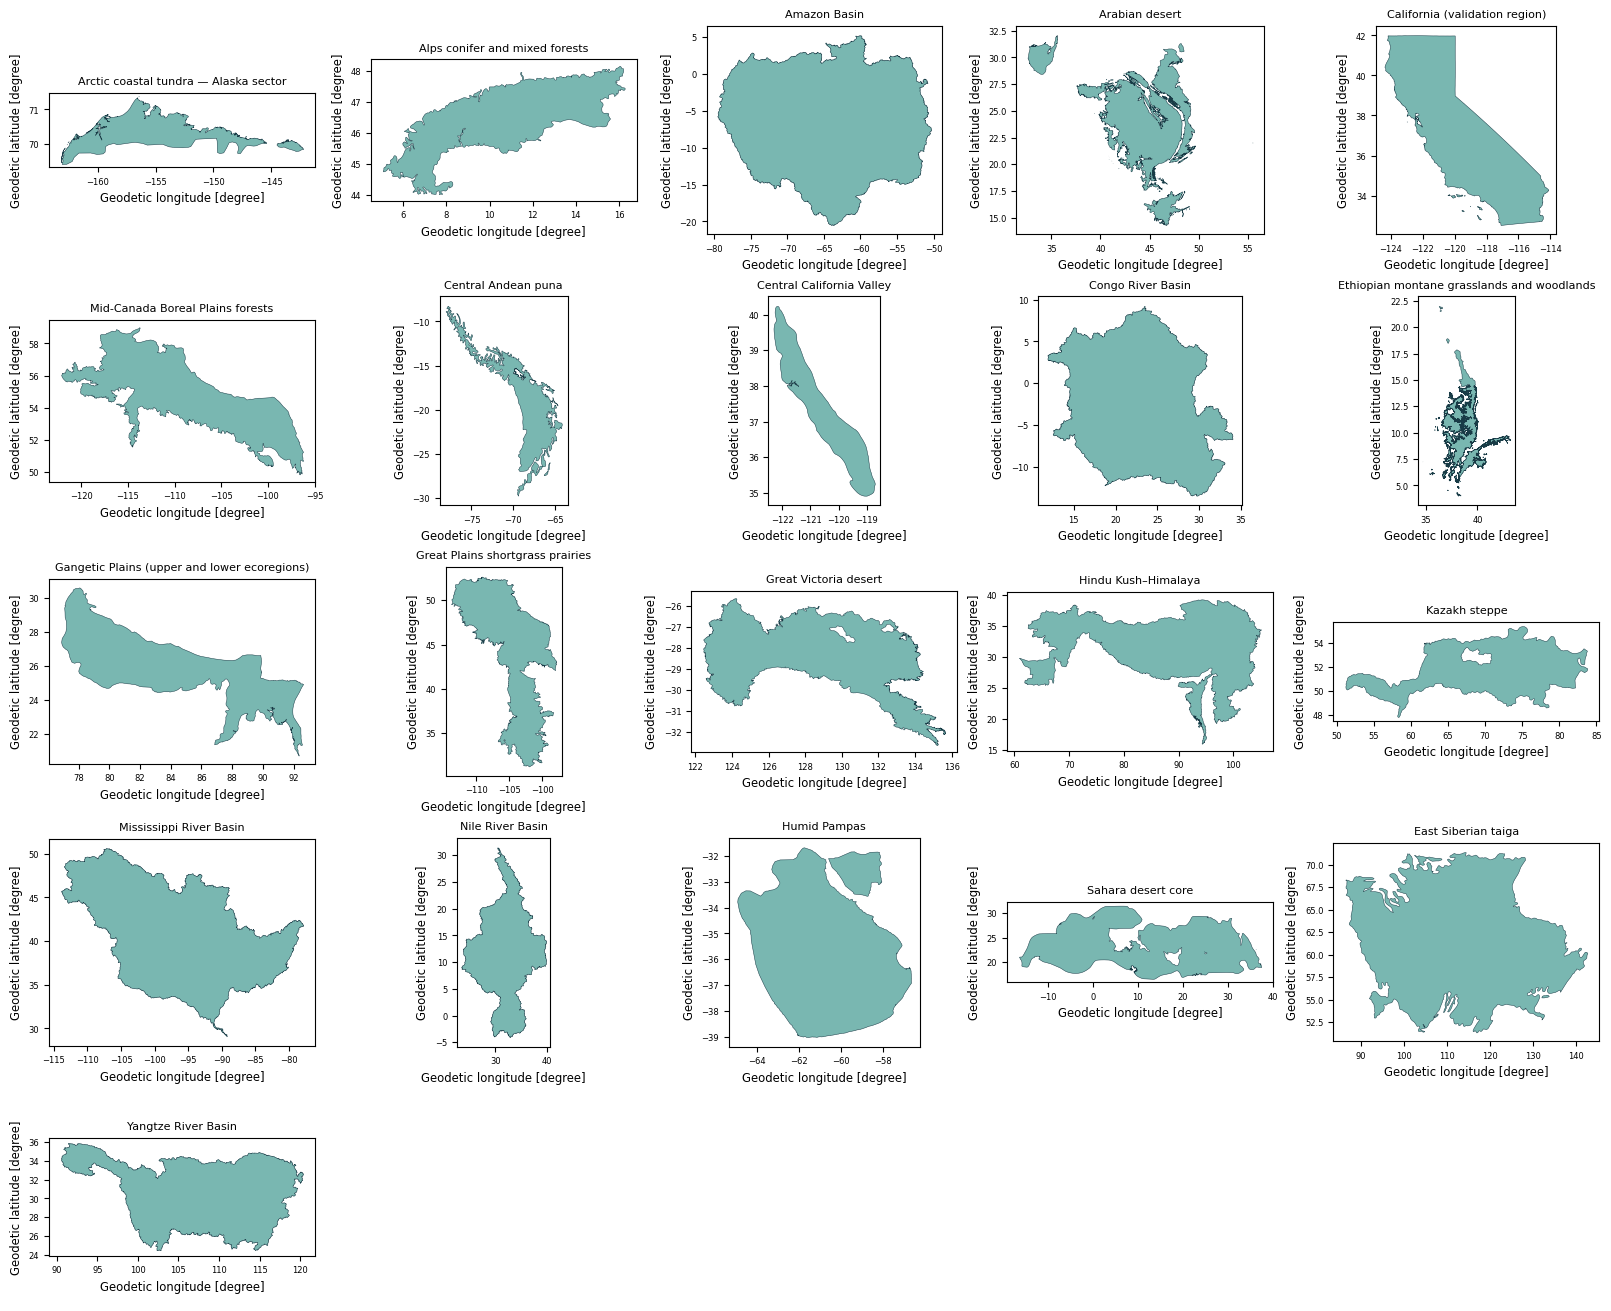

Checkpoint folder: /content/drive/MyDrive/RockIT/data/multi_checkpoints/5266b98bc72b7c82


In [3]:
BOUNDARY_PAYLOAD = '...'
BOUNDARIES=json.loads(gzip.decompress(base64.b64decode(BOUNDARY_PAYLOAD)))
REGIONS=gpd.GeoDataFrame.from_features(BOUNDARIES['features'],crs=4326)
REGIONS=REGIONS.sort_values('region_id').reset_index(drop=True)
if len(REGIONS)!=21 or REGIONS.region_id.duplicated().any():raise ValueError('Boundary registry mismatch')
if not REGIONS.geometry.is_valid.all():raise ValueError('Invalid geometry in embedded registry')
if not REGIONS.geometry.geom_type.isin(['Polygon','MultiPolygon']).all():raise ValueError('Non-polygon geometry')
print(REGIONS[['region_id','name','type']].to_string(index=False))
fig,axes=plt.subplots(5,5,figsize=(16,13),layout='constrained')
for ax,(_,r) in zip(axes.flat,REGIONS.iterrows()):
    gpd.GeoSeries([r.geometry],crs=4326).plot(ax=ax,color='#79b7b1',edgecolor='#183b46',linewidth=.35)
    ax.set_title(r['name'],fontsize=8);ax.tick_params(labelsize=6)
for ax in list(axes.flat)[len(REGIONS):]:ax.axis('off')
plt.show();plt.close(fig)
BOUNDARY_HASH=hashlib.sha256(json.dumps(BOUNDARIES,sort_keys=True).encode()).hexdigest()
METHOD='EPSG6933 vectorized cell intersection; polygon densification 0.025deg; fixed first-month common finite support'
RUN_KEY=hashlib.sha256(json.dumps({'boundary':BOUNDARY_HASH,'period':[START_MONTH,END_MONTH],'fields':FIELDS,'method':METHOD,'schema':1},sort_keys=True).encode()).hexdigest()[:16]
WORK=ROOT/'data'/'multi_checkpoints'/RUN_KEY
WORK.mkdir(parents=True,exist_ok=True)
(ROOT/'metadata'/'regions_multi.geojson').write_text(json.dumps(BOUNDARIES))
print('Checkpoint folder:',WORK)

## 2 · NASA login and one catalog search
Search once for the full period and select files by their NASA monthly filename token. Downloads are concurrent only in a small bounded queue; all NetCDF processing runs sequentially in the main thread. Missing granules or download failures stop processing without deleting completed checkpoints. Local mode needs one browser-downloaded `.nc4` file per requested month.

In [4]:
catalog={}
if DOWNLOAD_MODE=='earthaccess':
    import earthaccess
    auth=earthaccess.login(strategy='interactive')
    print('Searching monthly catalog once...')
    results=earthaccess.search_data(short_name='GLDAS_NOAH025_M',version='2.1',
        temporal=(ALL_MONTHS[0].start_time.strftime('%Y-%m-%d'),ALL_MONTHS[-1].end_time.strftime('%Y-%m-%d')),count=-1)
    for r in results:
        links=r.data_links()
        for month in ALL_MONTHS:
            token='A'+month.strftime('%Y%m')+'.021'
            if any(token in link for link in links):
                if str(month) in catalog:raise ValueError(f'Duplicate monthly granules for {month}')
                catalog[str(month)]=r
                break
    missing=[str(m) for m in MONTHS if str(m) not in catalog]
    if missing:raise ValueError(f'Missing catalog months: {missing}')
    print('Matching full-period granules:',len(catalog))
else:
    if not LOCAL_FILES.exists():raise FileNotFoundError(LOCAL_FILES)

def checkpoint_path(month):return WORK/f'{month}.json'
def fetch_month(month):
    if DOWNLOAD_MODE=='local':
        paths=list(LOCAL_FILES.rglob(f'*A{month.strftime("%Y%m")}*.nc4'))
        if len(paths)!=1:raise ValueError(f'Expected one local file for {month}; found {len(paths)}')
        return paths[0],{'month':str(month),'filename':paths[0].name,'source_urls':[],'access':'local browser download'}
    r=catalog[str(month)]
    folder=CACHE/str(month);folder.mkdir(exist_ok=True)
    paths=earthaccess.download([r],local_path=str(folder),threads=1)
    if len(paths)!=1:raise RuntimeError(f'Download failed for {month}')
    return Path(paths[0]),{'month':str(month),'filename':Path(paths[0]).name,'source_urls':r.data_links(),'access':'earthaccess'}
print('Access setup ready.')

Enter your Earthdata Login username: gurshabadsingh
Enter your Earthdata password: ··········
Searching monthly catalog once...
Matching full-period granules: 288
Access setup ready.


## 3 · Cached vectorized geographic weights
All intersecting cells get their intersection area in square metres. Polygons are densified in longitude/latitude before equal-area projection; grid cell edges follow latitude/longitude lines. Areas are computed once, then stored in a sparse matrix.

A fixed per-region land support uses cells finite in all four fields in January 2001. Later missing measurements reduce valid-area coverage, not the denominator. This pragmatic inferred land mask may omit baseline-missing cells permanently; its represented-land fraction is reported separately. It is not an authoritative land mask. Inspect low support fractions before analysis.

In [5]:
PROJECT=Transformer.from_crs(4326,6933,always_xy=True)
WEIGHTS_FILE=WORK/'weights.npz'
GRID_FILE=WORK/'grid_support.npz'
AREA_FILE=WORK/'region_support.json'
def edges(a):
    a=np.asarray(a,dtype=float)
    if len(a)<2 or not np.all(np.diff(a)>0):raise ValueError('Invalid grid coordinates')
    mids=(a[1:]+a[:-1])/2
    return np.r_[a[0]-(mids[0]-a[0]),mids,a[-1]+(a[-1]-mids[-1])]

def load_fields(ds,month):
    if ds.sizes.get('time')!=1:raise ValueError('Expected one monthly time record')
    if pd.Timestamp(ds.time.values[0]).to_period('M')!=month:raise ValueError('File month mismatch')
    if 'lat' not in ds.coords or 'lon' not in ds.coords:raise ValueError('Expected lat/lon')
    ds=ds.sortby('lat').sortby('lon')
    lat=ds.lat.values;lon=ds.lon.values
    if lon.max()>180:raise ValueError('Expected -180..180 longitudes')
    cols=[];units={}
    for field in FIELDS:
        if field not in ds:raise KeyError(field)
        a=ds[field].isel(time=0)
        if set(a.dims)!={'lat','lon'}:raise ValueError('Unexpected variable dimensions')
        u=str(a.attrs.get('units','')).strip();s=u.lower().replace(' ','').replace('**','').replace('^','')
        allowed={'k','kelvin'} if field=='AvgSurfT_inst' else ({'kgm-2','kg/m2'} if field=='SoilMoi0_10cm_inst' else {'kgm-2s-1','kg/m2/s'})
        if s not in allowed:raise ValueError(f'Unexpected units for {field}: {u}')
        cols.append(np.asarray(a.transpose('lat','lon').values,dtype=float).ravel());units[field]=u
    values=np.column_stack(cols);values[~np.isfinite(values)]=np.nan
    return values,units,lat,lon

def make_weights(lat,lon,baseline):
    le=edges(lat);oe=edges(lon);nr,nc=len(lat),len(lon)
    # In EPSG6933 x depends only on longitude, y only on latitude.
    xe=PROJECT.transform(oe,np.zeros(len(oe)))[0]
    ye=PROJECT.transform(np.zeros(len(le)),np.clip(le,-90,90))[1]
    row_indices=[];column_indices=[];areas=[];summaries=[]
    land=np.isfinite(baseline).all(axis=1)
    for i,r in tqdm(list(REGIONS.iterrows()),desc='Building area weights',unit='region'):
        geom=r.geometry;w,s,e,n=geom.bounds
        if e-w>180 or s<le[0] or n>le[-1]:raise ValueError(f'Unsupported domain: {r.region_id}')
        projected=shapely.transform(shapely.segmentize(geom,0.025),PROJECT.transform,interleaved=False)
        iy=np.flatnonzero((le[:-1]<n)&(le[1:]>s));ix=np.flatnonzero((oe[:-1]<e)&(oe[1:]>w))
        yy,xx=np.meshgrid(iy,ix,indexing='ij');yy=yy.ravel();xx=xx.ravel()
        boxes=shapely.box(xe[xx],ye[yy],xe[xx+1],ye[yy+1])
        shapely.prepare(projected)
        inside=shapely.covers(projected,boxes)
        weights=np.where(inside,(xe[xx+1]-xe[xx])*(ye[yy+1]-ye[yy]),0.0)
        boundary=(~inside)&shapely.intersects(projected,boxes)
        weights[boundary]=shapely.area(shapely.intersection(boxes[boundary],projected))
        flat=yy*nc+xx
        include=(weights>0)&land[flat]
        area=float(weights[include].sum())
        if area<=0:raise ValueError(f'No baseline represented land in {r.region_id}')
        row_indices.extend(np.full(include.sum(),i));column_indices.extend(flat[include]);areas.extend(weights[include])
        summaries.append({'region_id':r.region_id,'region_area_m2':float(projected.area),
            'grid_intersection_area_m2':float(weights.sum()),'baseline_land_area_m2':area,
            'baseline_land_fraction_of_region':area/float(projected.area),
            'represented_grid_cells':int(include.sum())})
    W=csr_matrix((areas,(row_indices,column_indices)),shape=(len(REGIONS),nr*nc))
    save_npz(WEIGHTS_FILE,W)
    np.savez_compressed(GRID_FILE,lat=lat,lon=lon)
    AREA_FILE.write_text(json.dumps(summaries,indent=2))
    return W,summaries

def summarize(values,units,W,month):
    finite=np.isfinite(values)
    numer=W@np.where(finite,values,0)
    denom=W@finite.astype(float)
    full=np.asarray(W.sum(axis=1)).ravel()
    means=np.divide(numer,denom,out=np.full_like(numer,np.nan),where=denom>0)
    coverage=denom/full[:,None]
    records=[]
    for i,rid in enumerate(REGIONS.region_id):
        for j,(field,variable) in enumerate(FIELDS.items()):
            records.append({'date':month.start_time.strftime('%Y-%m-%d'),'region':rid,'variable':variable,
                'value':float(means[i,j]) if np.isfinite(means[i,j]) else None,
                'unit':units[field],'valid_area_fraction':float(np.clip(coverage[i,j],0,1))})
    return records
print('Fast extraction functions ready.')

Fast extraction functions ready.


## 4 · Full-run progress, ETA and resumable extraction
The progress bar counts months extracted for ALL 21 regions. ETA applies to unfinished months, based on this session's speed, and becomes more useful after several months. A separate one-time weights progress bar appears on the first run. Benchmark runtime is extrapolated as a rough estimate, not a promise.

Keep Colab connected. Do not run multiple copies writing the same checkpoints. Failed months are not marked complete. Full-mode resume uses the same study period, region bundle and method. Change any of these and a new checkpoint key is created.

In [6]:
W=None;support_summary=None;reference_lat=None;reference_lon=None;weight_setup_seconds=0.0
if all(p.exists() for p in [WEIGHTS_FILE,GRID_FILE,AREA_FILE]):
    W=load_npz(WEIGHTS_FILE);support_summary=json.loads(AREA_FILE.read_text())
    with np.load(GRID_FILE) as grid:reference_lat=grid['lat'].copy();reference_lon=grid['lon'].copy()

def process_one(month,path,source):
    global W,support_summary,reference_lat,reference_lon,weight_setup_seconds
    with xr.open_dataset(path,mask_and_scale=True) as ds:
        values,units,lat,lon=load_fields(ds,month)
        if W is None:
            if month!=ALL_MONTHS[0]:raise ValueError('Build fixed weights from first study month')
            weight_start=time.perf_counter()
            W,support_summary=make_weights(lat,lon,values)
            weight_setup_seconds+=time.perf_counter()-weight_start
            reference_lat=lat.copy();reference_lon=lon.copy()
        elif not np.array_equal(lat,reference_lat) or not np.array_equal(lon,reference_lon):
            raise ValueError('Grid differs from cached weights')
        rows=summarize(values,units,W,month)
    source['sha256']=hashlib.sha256(path.read_bytes()).hexdigest()
    payload={'rows':rows,'source':source}
    target=checkpoint_path(month);temp=target.with_suffix('.tmp')
    temp.write_text(json.dumps(payload,allow_nan=False));temp.replace(target)
    return payload

completed=[];pending=[]
for month in MONTHS:
    p=checkpoint_path(month)
    if p.exists() and W is not None:
        payload=json.loads(p.read_text())
        if len(payload['rows'])!=4*len(REGIONS):raise ValueError(f'Corrupt checkpoint {p}')
        completed.append(month)
    else:pending.append(month)
print('Resuming:',len(completed),'complete;',len(pending),'remaining.')
start_clock=time.perf_counter();fresh=0
bar=tqdm(total=len(MONTHS),initial=len(completed),desc='All regions extracted',unit='month',smoothing=.15)
# Set the reference point so resumed work is excluded from rate/ETA calculation.
bar.last_print_n=bar.n;bar.start_t=bar._time();bar.last_print_t=bar.start_t
pool=ThreadPoolExecutor(max_workers=PREFETCH);futures={}
try:
    for k in range(min(PREFETCH,len(pending))):futures[k]=pool.submit(fetch_month,pending[k])
    for k,month in enumerate(pending):
        path,source=futures.pop(k).result()
        try:process_one(month,path,source)
        except Exception:
            print('Stopped at',month,'— fix the error and rerun. Checkpoints:',WORK)
            raise
        finally:
            if DOWNLOAD_MODE=='earthaccess' and not KEEP_RAW and path.exists():path.unlink()
        fresh+=1;bar.update(1);bar.set_postfix(last=str(month),regions=len(REGIONS))
        nxt=k+PREFETCH
        if nxt<len(pending):futures[nxt]=pool.submit(fetch_month,pending[nxt])
finally:
    for f in futures.values():f.cancel()
    pool.shutdown(wait=True,cancel_futures=True);bar.close()
elapsed=time.perf_counter()-start_clock
print(f'Completed {len(MONTHS)} requested months across {len(REGIONS)} regions.')
if fresh:
    per_month=max(0,elapsed-weight_setup_seconds)/fresh
    remaining_full=sum(not checkpoint_path(m).exists() for m in ALL_MONTHS)
    print(f'One-time weight setup: {weight_setup_seconds:.1f} seconds. Subsequent work: {per_month:.1f} sec/new month.')
    print(f'Rough remaining full-run estimate: {remaining_full*per_month/60:.1f} minutes; network speed can change.')
display(pd.DataFrame(support_summary))

Resuming: 0 complete; 288 remaining.


All regions extracted:   0%|          | 0/288 [00:00<?, ?month/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Building area weights:   0%|          | 0/21 [00:00<?, ?region/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (283 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Completed 288 requested months across 21 regions.
One-time weight setup: 27.2 seconds. Subsequent work: 1.1 sec/new month.
Rough remaining full-run estimate: 0.0 minutes; network speed can change.


,region_id,region_area_m2,grid_intersection_area_m2,baseline_land_area_m2,baseline_land_fraction_of_region,represented_grid_cells
0,alaska_tundra,4.970252e+10,4.970252e+10,4.441192e+10,0.893555,228
1,alps,1.498708e+11,1.498708e+11,1.498708e+11,1.000000,363
2,amazon,5.888269e+12,5.888269e+12,5.879813e+12,0.998564,8042
3,arabian_desert,8.478299e+11,8.478299e+11,8.459880e+11,0.997828,1633
4,california,4.098186e+11,4.098186e+11,4.038005e+11,0.985315,718
5,canadian_boreal,5.697197e+11,5.697197e+11,5.302068e+11,0.930645,1419
6,central_andean_puna,5.832819e+11,5.832819e+11,5.795713e+11,0.993638,1131
7,central_valley,4.600102e+10,4.600102e+10,4.600102e+10,1.000000,116
8,congo,3.689187e+12,3.689187e+12,3.645651e+12,0.988199,5043
9,ethiopian_highlands,2.346452e+11,2.346452e+11,2.342291e+11,0.998227,600


## 5 · Validate and export (preserves California outputs)
Coverage is valid area relative to the fixed baseline represented-land area. Baseline support fraction relative to the full region is also exported for review. No interpolation or fabricated measurements. The full CSV is only written after every requested month is checkpointed. Low coverage is flagged, not concealed.

For the analysis notebook change:
```
INPUT = ROOT/'data/regional_monthly_multi.csv'
```
and change its metadata path to `ROOT/'metadata/metadata_multi.json'`. The existing clustering code then attempts training once ≥20 complete fingerprints exist. Retain separation/stability checks even though training is a required project step.

In [7]:
records=[];sources=[]
for month in MONTHS:
    p=checkpoint_path(month)
    if not p.exists():raise ValueError(f'Month not completed: {month}')
    payload=json.loads(p.read_text());records.extend(payload['rows']);sources.append(payload['source'])
table=pd.DataFrame(records)
table['value']=pd.to_numeric(table.value,errors='raise')
if len(table)!=len(MONTHS)*len(REGIONS)*4:raise ValueError('Record count mismatch')
if table.duplicated(['date','region','variable']).any():raise ValueError('Duplicate output keys')
if not table.valid_area_fraction.between(0,1).all():raise ValueError('Invalid spatial coverage')
if table.groupby(['region','variable']).size().ne(len(MONTHS)).any():raise ValueError('Incomplete series')
if table.groupby('variable').unit.nunique().ne(1).any():raise ValueError('Units changed between months')
table=table.sort_values(['date','region','variable']).reset_index(drop=True)
name='regional_monthly_multi_BENCHMARK.csv' if MODE=='benchmark' else 'regional_monthly_multi.csv'
target=ROOT/'data'/name;csv=table.to_csv(index=False)
if target.exists() and target.read_text()!=csv and not OVERWRITE_EXISTING:
    raise FileExistsError(f'{target} differs. Back it up and set OVERWRITE_EXISTING=True if intentional.')
temp=target.with_suffix('.tmp');temp.write_text(csv);temp.replace(target)
quality=table.groupby(['region','variable']).agg(months=('value','size'),missing=('value',lambda s:s.isna().sum()),min_coverage=('valid_area_fraction','min'))
quality.to_csv(WORK/'quality_report.csv')
metadata={'product':'GLDAS_NOAH025_M','version':'2.1','mode':MODE,
    'period':[str(MONTHS[0]),str(MONTHS[-1])],'baseline_month':START_MONTH,'region_count':len(REGIONS),
    'regions':[f['properties'] for f in BOUNDARIES['features']],
    'boundary_hash':BOUNDARY_HASH,'weighting':METHOD,'region_support':support_summary,
    'coverage_definition':'valid intersection-weighted area / fixed first-month common-finite represented-land area',
    'source_granules':sources,'native_units':table.groupby('variable').unit.first().to_dict(),
    'created_utc':datetime.now(timezone.utc).isoformat(),'checkpoint_key':RUN_KEY,
    'limitations':['Regions overlap and differ in size/type','HKH copy publisher/source item recorded; verify reuse terms',
      'Baseline land mask inferred from common finite values; not authoritative land mask','Historical GLDAS modeled estimates, not direct observations or causal evidence']}
meta_name='metadata_multi_BENCHMARK.json' if MODE=='benchmark' else 'metadata_multi.json'
(ROOT/'metadata'/meta_name).write_text(json.dumps(metadata,indent=2,allow_nan=False))
print('CSV saved:',target,'| Rows:',len(table))
print('Metadata:',ROOT/'metadata'/meta_name)
print('Geometry:',ROOT/'metadata/regions_multi.geojson')
print('Coverage report:',WORK/'quality_report.csv')
display(quality);display(table.head())
if MODE=='benchmark':print('Inspect boundaries/support and coverage. Set MODE=full then Run all; these checkpoints will be reused.')

CSV saved: /content/drive/MyDrive/RockIT/data/regional_monthly_multi.csv | Rows: 24192
Metadata: /content/drive/MyDrive/RockIT/metadata/metadata_multi.json
Geometry: /content/drive/MyDrive/RockIT/metadata/regions_multi.geojson
Coverage report: /content/drive/MyDrive/RockIT/data/multi_checkpoints/5266b98bc72b7c82/quality_report.csv


months  missing  min_coverage
region         variable                                          
alaska_tundra  evapotranspiration      288        0           1.0
               precipitation           288        0           1.0
               soil_moisture           288        0           1.0
               surface_temperature     288        0           1.0
alps           evapotranspiration      288        0           1.0
...                                    ...      ...           ...
siberian_taiga surface_temperature     288        0           1.0
yangtze        evapotranspiration      288        0           1.0
               precipitation           288        0           1.0
               soil_moisture           288        0           1.0
               surface_temperature     288        0           1.0

[84 rows x 3 columns]

,date,region,variable,value,unit,valid_area_fraction
0,2001-01-01,alaska_tundra,evapotranspiration,0.000001,kg m-2 s-1,1.0
1,2001-01-01,alaska_tundra,precipitation,0.000007,kg m-2 s-1,1.0
2,2001-01-01,alaska_tundra,soil_moisture,23.753559,kg m-2,1.0
3,2001-01-01,alaska_tundra,surface_temperature,250.359688,K,1.0
4,2001-01-01,alps,evapotranspiration,0.000001,kg m-2 s-1,1.0


## Troubleshooting / scientific review
- NASA 403 / EulaNotAccepted: same Earthdata account in browser and Colab; complete requested authorization/agreements and reconnect. No code can bypass account permissions.
- A transient download failure: rerun; successful monthly checkpoints are retained. The small download queue may finish a couple of files before stopping.
- Runtime reset: reconnect Drive, Run all; weights and extracted months resume. Temporary raw files may need downloading again.
- Boundary/support problems: inspect geometry and support report before full mode. Do not silently replace polygons, rename whole California as Central Valley, or lower analysis thresholds to make data pass.
- No model / <20 valid regions after analysis: inspect data coverage and fingerprint completeness; do not duplicate regions as fake samples. HKH/Indus and California/Central Valley overlap.
- Old California run: preserved separately. Its CSV is a useful cross-check; cached summaries cannot reconstruct discarded raw global files for new regions.

Sources: RESOLVE Ecoregions 2017 (Dinerstein et al. 2017, CC BY 4.0), HydroBASINS standard v1c (HydroSHEDS), EPA Central California Valley ecoregion, US Census 2024 cartographic state boundaries, HKH published boundary copy. Exact source URLs and basin IDs are embedded in each feature. Cite HydroBASINS and GLDAS per their source guidance. The baseline mask and weighting method must be disclosed with results.